# Cristiano Ronaldo — Assists Analysis

This notebook creates four visualizations for the assists article:
1. Assists by club
2. Assists by season
3. Assists by competition
4. Distribution of assists per match

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

project_candidates = (Path.cwd(), *Path.cwd().parents)

ROOT = next(
    (
        candidate for candidate in project_candidates
        if (candidate / "data" / "matches").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        f"Could not find data/matches. Current directory: {Path.cwd()}"
    )

MATCH_DIR = ROOT / "data" / "matches"
CHART_DIR = ROOT / "public" / "images" / "articles"
CSV_DIR = ROOT / "public" / "data" / "articles"

CHART_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)

files = sorted(MATCH_DIR.glob("*.json"))

if not files:
    raise FileNotFoundError(
        f"No season JSON files found in {MATCH_DIR}"
    )

records = []
for file in files:
    with file.open("r", encoding="utf-8") as f:
        season_matches = json.load(f)

    if isinstance(season_matches, list):
        records.extend(season_matches)
    elif isinstance(season_matches, dict):
        records.extend(season_matches.get("matches", []))

df = pd.DataFrame(records)

required = {"date", "season", "team", "competition", "assists"}
missing = required - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required match-log columns: {sorted(missing)}"
    )

df["assists"] = pd.to_numeric(
    df["assists"], errors="coerce"
).fillna(0)

if "goals" not in df.columns:
    df["goals"] = 0

df["goals"] = pd.to_numeric(
    df["goals"], errors="coerce"
).fillna(0)

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["season", "team", "competition"]).copy()

print(f"Project root: {ROOT.resolve()}")
print(f"Match directory: {MATCH_DIR.resolve()}")
print(f"Loaded {len(df):,} logged matches from {len(files)} season files.")
print(f"Total assists in this dataset: {int(df['assists'].sum()):,}")

Project root: C:\Users\soham\OneDrive\Desktop\ronaldo-archive\ronaldo-archive
Match directory: C:\Users\soham\OneDrive\Desktop\ronaldo-archive\ronaldo-archive\data\matches
Loaded 1,342 logged matches from 25 season files.
Total assists in this dataset: 261


## 1. Assists by club

Portugal is excluded from this chart because it is a national team, not a club. This chart sums the assists recorded in the archive for each club.

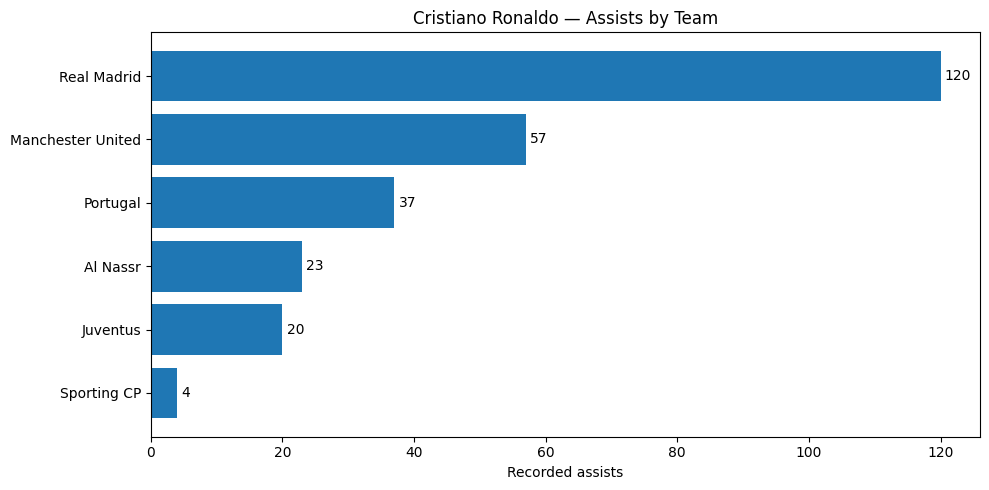

In [9]:
club_df = df.groupby("team", as_index=False)["assists"].sum()
club_df = club_df.sort_values("assists", ascending=True)
club_df.to_csv(CSV_DIR / "assists_by_club.csv", index=False)

fig, ax = plt.subplots(figsize=(10, max(5, len(club_df) * 0.55)))
ax.barh(club_df["team"], club_df["assists"])
ax.set_title("Cristiano Ronaldo — Assists by Team")
ax.set_xlabel("Recorded assists")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], padding=3, fmt="%.0f")
fig.tight_layout()
fig.savefig(CHART_DIR / "assists_by_club.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Assists by season

Season totals include every match in the archive for that season, including Portugal matches. If you want club-only season totals, filter out Portugal before grouping.

,season,assists
0,2002/03,4
1,2003/04,9
2,2004/05,12
3,2005/06,10
4,2006/07,16
5,2007/08,8
6,2008/09,9
7,2009/10,11
8,2010/11,17
9,2011/12,18


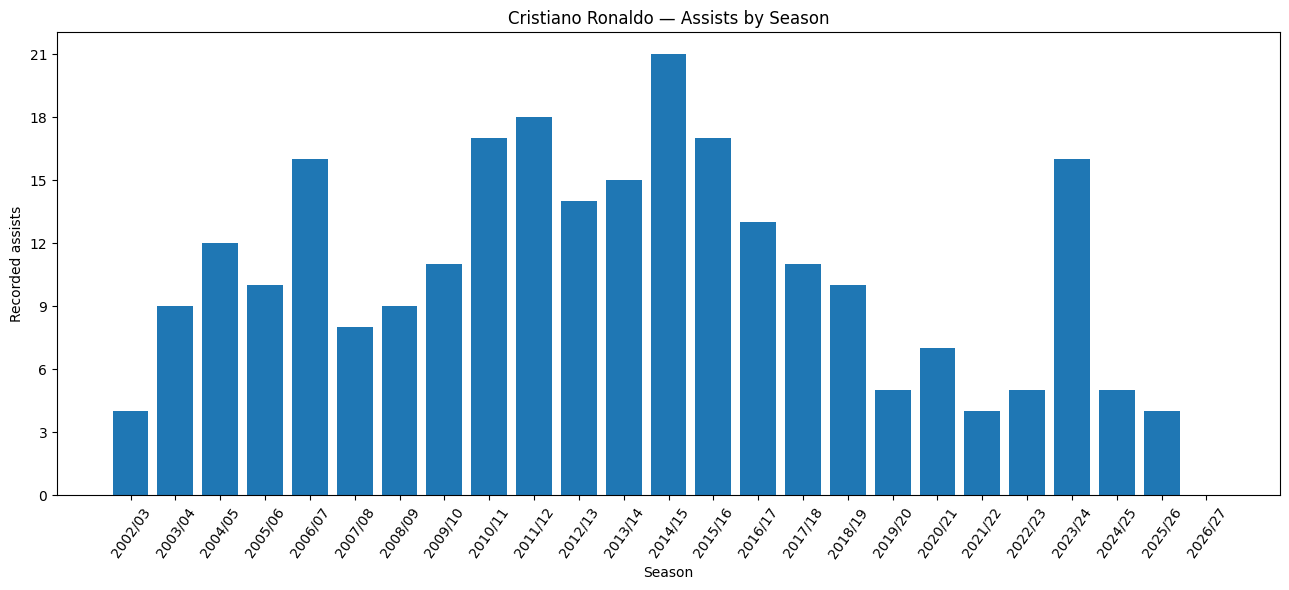

In [11]:
from matplotlib.ticker import MaxNLocator
from IPython.display import display

season_df = df.groupby("season", as_index=False)["assists"].sum()

season_order = sorted(
    season_df["season"].unique(),
    key=lambda s: int(str(s).split("/")[0])
)

season_df["season"] = pd.Categorical(
    season_df["season"],
    categories=season_order,
    ordered=True
)

season_df = season_df.sort_values("season")
season_df["season"] = season_df["season"].astype(str)

season_df.to_csv(CSV_DIR / "assists_by_season.csv", index=False)

# Display the statistics table
display(season_df)

# Create the chart
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(season_df["season"], season_df["assists"])

ax.set_title("Cristiano Ronaldo — Assists by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Recorded assists")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.tick_params(axis="x", rotation=55)

fig.tight_layout()
fig.savefig(
    CHART_DIR / "assists_by_season.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

## 3. Assists by competition

This chart combines all competitions in the archive, including international competitions. Use the CSV to inspect the exact values.

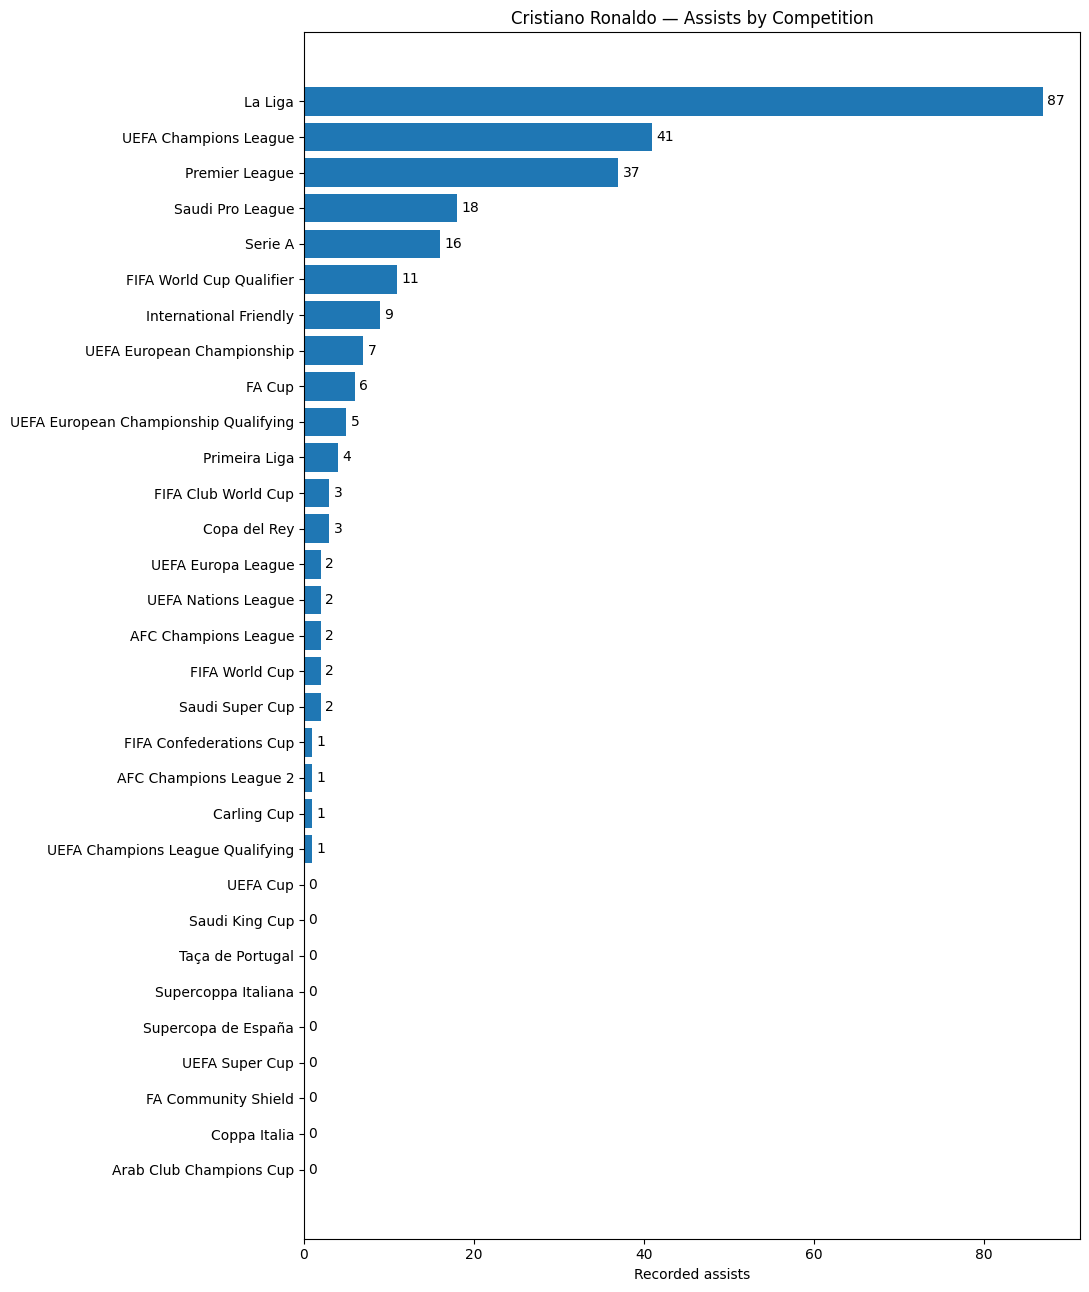

In [12]:
competition_df = df.groupby("competition", as_index=False)["assists"].sum()
competition_df = competition_df.sort_values("assists", ascending=True)
competition_df.to_csv(CSV_DIR / "assists_by_competition.csv", index=False)

fig, ax = plt.subplots(figsize=(11, max(6, len(competition_df) * 0.42)))
ax.barh(competition_df["competition"], competition_df["assists"])
ax.set_title("Cristiano Ronaldo — Assists by Competition")
ax.set_xlabel("Recorded assists")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], padding=3, fmt="%.0f")
fig.tight_layout()
fig.savefig(CHART_DIR / "assists_by_competition.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Distribution of assists per match

The frequency chart groups matches into 0, 1, 2, 3, and 4+ assists. The 4+ category is grouped to avoid a very sparse tail. The accompanying table lists matches where Ronaldo recorded at least three assists, for follow-up checking before writing the article.

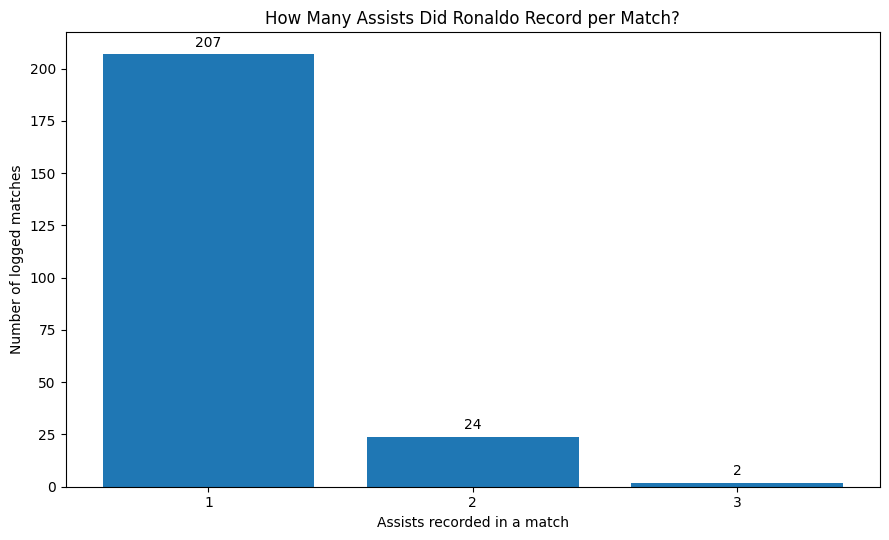

,date,season,team,opponent,competition,scoreFor,scoreAgainst,assists
281,2008-03-29,2007/08,Manchester United,Aston Villa,Premier League,4,0,3
435,2011-05-21,2010/11,Real Madrid,Almeria,La Liga,8,1,3


In [14]:
distribution = df.copy()
distribution["assist_group"] = distribution["assists"].apply(
    lambda n: "4+" if n >= 4 else str(int(n))
)
group_order = ["1", "2", "3"]
distribution_df = (
    distribution["assist_group"]
    .value_counts()
    .reindex(group_order, fill_value=0)
    .rename_axis("assists_in_match")
    .reset_index(name="matches")
)
distribution_df.to_csv(CSV_DIR / "assist_match_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(distribution_df["assists_in_match"], distribution_df["matches"])
ax.set_title("How Many Assists Did Ronaldo Record per Match?")
ax.set_xlabel("Assists recorded in a match")
ax.set_ylabel("Number of logged matches")
ax.bar_label(ax.containers[0], padding=3, fmt="%.0f")
fig.tight_layout()
fig.savefig(CHART_DIR / "assist_match_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

three_plus = df[df["assists"] >= 3].copy()
columns = [c for c in ["date", "season", "team", "opponent", "competition", "scoreFor", "scoreAgainst", "assists"] if c in three_plus.columns]
three_plus = three_plus[columns].sort_values("date")
three_plus.to_csv(CSV_DIR / "matches_with_3plus_assists.csv", index=False)
display(three_plus)